<img src="https://www.pucsp.br/sites/default/files/download/brasao-PUCSP-assinatura-pref-pb.png" width="220" alt="PUC-SP"/>

# Laboratório 4: Modelos Ensemble (Bagging, Boosting e Stacking)
**Pontifícia Universidade Católica de São Paulo — PUC-SP**  
**Disciplina:** Inteligência Artificial e Aprendizado de Máquina  
**Alunos / Dupla:**
- **Cesar Gritti** — GitHub: [@Ce-22](https://github.com/Ce-22) — E-mail: cesargritti05@gmail.com
- **Pedro Isamu Yoshissaro** — GitHub: [@knutzin](https://github.com/knutzin) — E-mail: pedro.isamu2005@gmail.com

---

## 1. Fundamentos Teóricos dos Modelos Ensemble
Modelos *ensemble* combinam múltiplos estimadores base para produzir um modelo preditivo com maior poder de generalização do que qualquer modelo individual.

### Bagging (Bootstrap Aggregating)
- **Princípio:** Redução da **variância**. Ajusta estimadores independentes em subamostras com reposição (*bootstrap*) do conjunto de treino e agrega as predições por votação majoritária ou média.
- **Exemplos:** `BaggingClassifier`, `RandomForestClassifier`.
- **Referências:**
  - [GeeksforGeeks — Bagging vs Boosting vs Stacking](https://www.geeksforgeeks.org/machine-learning/bagging-vs-boosting-vs-stacking/)
  - [Scikit-Learn — Bagging Classifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html)

### Boosting
- **Princípio:** Redução do **viés** (*bias*). Ajusta estimadores sequencialmente, onde cada novo modelo busca corrigir os erros residuais e focar nos exemplos classificados incorretamente pelos modelos anteriores.
- **Exemplos:** `AdaBoostClassifier`, `GradientBoostingClassifier`, `HistGradientBoostingClassifier`.
- **Referências:**
  - [GeeksforGeeks — Boosting in Machine Learning](https://www.geeksforgeeks.org/machine-learning/boosting-in-machine-learning/)
  - [Scikit-Learn — Gradient Boosting](https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosted-trees)

### Stacking (Stacked Generalization)
- **Princípio:** Combinação sinérgica de modelos **heterogêneos**. As predições de múltiplos estimadores de base (ex.: Florestas Aleatórias, SVM e Redes Neurais Artificiais) alimentam um modelo final (*meta-learner*, como a Regressão Logística), que aprende a melhor combinação ponderada.
- **Exemplos:** `StackingClassifier`.
- **Referências:**
  - [Scikit-Learn — Stacking Classifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html)
  - [Scikit-Learn Ensemble Guide](https://scikit-learn.org/stable/modules/ensemble.html#stacking)


In [1]:
# Dependências e Configuração do Ambiente
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from vega_datasets import data

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
    StackingClassifier
)
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Ambiente configurado com sucesso!")


Ambiente configurado com sucesso!


## 2. Carregamento dos Dados: Dataset `seattle_weather`
Utilizamos o conjunto de dados **`seattle_weather`** da biblioteca `vega_datasets`. O dataset contém medições meteorológicas diárias ao longo de 4 anos consecutivos em Seattle, apresentando atributos contínuos de precipitação, temperaturas e vento, e como variável-alvo a condição de tempo (`weather`).


In [2]:
# 1. Carregar dataset do vega_datasets
df = data.seattle_weather()
print("Formato do dataset:", df.shape)
print("\nDistribuição das classes climáticas:")
print(df['weather'].value_counts())
df.head()


Formato do dataset: (1461, 6)

Distribuição das classes climáticas:
weather
sun        714
fog        411
rain       259
drizzle     54
snow        23
Name: count, dtype: int64


,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


## 3. Engenharia de Recursos (Feature Engineering) e Pré-Processamento
Para enriquecer a capacidade discriminativa dos ensembles:
1. **`temp_range`**: Amplitude térmica diária (`temp_max - temp_min`).
2. **`temp_avg`**: Temperatura média diária.
3. **Variáveis Temporais**: `month`, `day`, `dayofweek`, `is_weekend`.
4. **`precip_3d_rolling`**: Média móvel da precipitação dos últimos 3 dias.
5. **`wind_temp_ratio`**: Razão entre intensidade de vento e temperatura máxima relativa.


In [3]:
df_proc = df.copy()
df_proc['date'] = pd.to_datetime(df_proc['date'])
df_proc['temp_range'] = df_proc['temp_max'] - df_proc['temp_min']
df_proc['temp_avg'] = (df_proc['temp_max'] + df_proc['temp_min']) / 2.0
df_proc['month'] = df_proc['date'].dt.month
df_proc['day'] = df_proc['date'].dt.day
df_proc['dayofweek'] = df_proc['date'].dt.dayofweek
df_proc['is_weekend'] = (df_proc['dayofweek'] >= 5).astype(int)
df_proc['precip_3d_rolling'] = df_proc['precipitation'].rolling(window=3, min_periods=1).mean()
df_proc['wind_temp_ratio'] = df_proc['wind'] / (df_proc['temp_max'] + 10.0)

feature_cols = [
    'precipitation', 'temp_max', 'temp_min', 'wind',
    'temp_range', 'temp_avg', 'month', 'day', 'dayofweek',
    'is_weekend', 'precip_3d_rolling', 'wind_temp_ratio'
]

X = df_proc[feature_cols].copy()
le = LabelEncoder()
y = le.fit_transform(df_proc['weather'])
target_names = list(le.classes_)

# Divisão Estratificada 75% Treino / 25% Teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"Features preditoras ({len(feature_cols)}):", feature_cols)
print("Classes mapeadas:", dict(zip(range(len(target_names)), target_names)))
print(f"Amostras de treino: {X_train.shape[0]}, Amostras de teste: {X_test.shape[0]}")


Features preditoras (12): ['precipitation', 'temp_max', 'temp_min', 'wind', 'temp_range', 'temp_avg', 'month', 'day', 'dayofweek', 'is_weekend', 'precip_3d_rolling', 'wind_temp_ratio']
Classes mapeadas: {0: 'drizzle', 1: 'fog', 2: 'rain', 3: 'snow', 4: 'sun'}
Amostras de treino: 1095, Amostras de teste: 366


## 4. Modelo Baseline: Árvore de Decisão Individual
Treinamos uma `DecisionTreeClassifier` única sem regularização como ponto de referência para medir o ganho trazido pelos métodos ensemble.


In [4]:
baseline_dt = DecisionTreeClassifier(random_state=42)
baseline_dt.fit(X_train, y_train)
y_pred_dt = baseline_dt.predict(X_test)

acc_dt = accuracy_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt, average='macro')

print(f"[Baseline] Decision Tree - Acurácia: {acc_dt:.4f} | F1-Macro: {f1_dt:.4f}")
print("\nRelatório de Classificação da Árvore Isolada:")
print(classification_report(y_test, y_pred_dt, target_names=target_names))


[Baseline] Decision Tree - Acurácia: 0.5601 | F1-Macro: 0.4232

Relatório de Classificação da Árvore Isolada:
              precision    recall  f1-score   support

     drizzle       0.00      0.00      0.00        13
         fog       0.48      0.41      0.44       103
        rain       0.34      0.38      0.36        65
        snow       0.50      0.67      0.57         6
         sun       0.74      0.75      0.74       179

    accuracy                           0.56       366
   macro avg       0.41      0.44      0.42       366
weighted avg       0.56      0.56      0.56       366



## 5. Pilar 1: Bagging (Bootstrap Aggregation)
Implementamos dois modelos baseados em agregação bootstrap:
1. **`BaggingClassifier`**: Composto por 100 árvores de decisão completas ajustadas sobre amostras com reposição.
2. **`RandomForestClassifier`**: Incorpora adicionalmente a seleção aleatória de subconjuntos de atributos (`max_features='sqrt'`) em cada split, descorrelacionando as árvores.


In [5]:
bagging_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    random_state=42
)
bagging_clf.fit(X_train, y_train)
y_pred_bag = bagging_clf.predict(X_test)

rf_clf = RandomForestClassifier(
    n_estimators=100,
    max_features='sqrt',
    random_state=42
)
rf_clf.fit(X_train, y_train)
y_pred_rf = rf_clf.predict(X_test)

print(f"[Bagging] BaggingClassifier (100 DTs) - Acurácia: {accuracy_score(y_test, y_pred_bag):.4f} | F1-Macro: {f1_score(y_test, y_pred_bag, average='macro'):.4f}")
print(f"[Bagging] RandomForestClassifier     - Acurácia: {accuracy_score(y_test, y_pred_rf):.4f} | F1-Macro: {f1_score(y_test, y_pred_rf, average='macro'):.4f}")


[Bagging] BaggingClassifier (100 DTs) - Acurácia: 0.7131 | F1-Macro: 0.5118
[Bagging] RandomForestClassifier     - Acurácia: 0.7049 | F1-Macro: 0.5079


## 6. Pilar 2: Boosting (AdaBoost, Gradient Boosting e HistGradientBoosting)
O Boosting treina modelos sequenciais onde cada novo estimador foca nos erros dos anteriores:
1. **`AdaBoostClassifier`**: Pondera os pesos das instâncias incorretas a cada rodada.
2. **`GradientBoostingClassifier`**: Otimiza iterativamente a função de perda de entropia cruzada multiclasse ajustando árvores aos pseudo-resíduos negativos do gradiente.
3. **`HistGradientBoostingClassifier`**: Versão baseada em histogramas (estilo LightGBM), altamente eficiente.


In [6]:
adaboost_clf = AdaBoostClassifier(n_estimators=100, random_state=42)
adaboost_clf.fit(X_train, y_train)
y_pred_ada = adaboost_clf.predict(X_test)

gb_clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb_clf.fit(X_train, y_train)
y_pred_gb = gb_clf.predict(X_test)

hgb_clf = HistGradientBoostingClassifier(max_iter=100, random_state=42)
hgb_clf.fit(X_train, y_train)
y_pred_hgb = hgb_clf.predict(X_test)

print(f"[Boosting] AdaBoost               - Acurácia: {accuracy_score(y_test, y_pred_ada):.4f} | F1-Macro: {f1_score(y_test, y_pred_ada, average='macro'):.4f}")
print(f"[Boosting] Gradient Boosting      - Acurácia: {accuracy_score(y_test, y_pred_gb):.4f} | F1-Macro: {f1_score(y_test, y_pred_gb, average='macro'):.4f}")
print(f"[Boosting] Hist Gradient Boosting - Acurácia: {accuracy_score(y_test, y_pred_hgb):.4f} | F1-Macro: {f1_score(y_test, y_pred_hgb, average='macro'):.4f}")


[Boosting] AdaBoost               - Acurácia: 0.6694 | F1-Macro: 0.4616
[Boosting] Gradient Boosting      - Acurácia: 0.6721 | F1-Macro: 0.4533
[Boosting] Hist Gradient Boosting - Acurácia: 0.6694 | F1-Macro: 0.4618


## 7. Pilar 3: Stacking (Stacked Generalization Heterogêneo)
Combinamos uma família heterogênea de aprendizes base com diferentes vieses indutivos:
- **Random Forest** (baseado em árvores e bootstrap)
- **SVM com kernel RBF** (baseado em margem máxima de separação espacial com `StandardScaler`)
- **Rede Neural Artificial / MLP** (baseado em representações distribuídas com 2 camadas ocultas `(64, 32)`)
- **HistGradientBoosting** (baseado em gradiente estocástico)

As probabilidades preditas em validação cruzada out-of-fold pelos modelos base são combinadas por um meta-classificador de **Regressão Logística**.


In [7]:
base_learners = [
    ('rf', make_pipeline(SimpleImputer(strategy='median'),
                         RandomForestClassifier(n_estimators=100, random_state=42))),
    ('svm', make_pipeline(SimpleImputer(strategy='median'),
                          StandardScaler(),
                          SVC(probability=True, kernel='rbf', C=1.0, random_state=42))),
    ('mlp', make_pipeline(SimpleImputer(strategy='median'),
                          StandardScaler(),
                          MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=800, random_state=42))),
    ('hgb', make_pipeline(SimpleImputer(strategy='median'),
                          HistGradientBoostingClassifier(max_iter=100, random_state=42)))
]

stacking_clf = StackingClassifier(
    estimators=base_learners,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5
)

stacking_clf.fit(X_train, y_train)
y_pred_stack = stacking_clf.predict(X_test)

print(f"[Stacking] StackingClassifier Heterogêneo - Acurácia: {accuracy_score(y_test, y_pred_stack):.4f} | F1-Macro: {f1_score(y_test, y_pred_stack, average='macro'):.4f}")
print("\nRelatório Detalhado de Classificação do Stacking:")
print(classification_report(y_test, y_pred_stack, target_names=target_names))


[Stacking] StackingClassifier Heterogêneo - Acurácia: 0.7077 | F1-Macro: 0.4883

Relatório Detalhado de Classificação do Stacking:
              precision    recall  f1-score   support

     drizzle       0.00      0.00      0.00        13
         fog       0.60      0.68      0.64       103
        rain       0.61      0.31      0.41        65
        snow       0.60      0.50      0.55         6
         sun       0.79      0.93      0.85       179

    accuracy                           0.71       366
   macro avg       0.52      0.48      0.49       366
weighted avg       0.67      0.71      0.68       366



## 8. Avaliação Consolidada e Validação Cruzada Estratificada (5-Fold)
Comparamos todos os modelos sob o mesmo protocolo de validação cruzada de 5 pastas estratificadas no conjunto de treino e avaliação cega no conjunto holdout de teste (25%).


In [8]:
all_models = {
    'Decision Tree (Baseline)': baseline_dt,
    'Bagging (DT)': bagging_clf,
    'Random Forest': rf_clf,
    'AdaBoost': adaboost_clf,
    'Gradient Boosting': gb_clf,
    'Hist Gradient Boosting': hgb_clf,
    'Stacking Ensemble': stacking_clf
}

cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tabela_comparativa = []

for name, model in all_models.items():
    cv_res = cross_validate(model, X_train, y_train, cv=cv_strat, scoring=['accuracy', 'f1_macro'])
    y_pred = model.predict(X_test)
    
    tabela_comparativa.append({
        'Modelo': name,
        'CV Acurácia': cv_res['test_accuracy'].mean(),
        'CV F1-Macro': cv_res['test_f1_macro'].mean(),
        'Teste Acurácia': accuracy_score(y_test, y_pred),
        'Teste F1-Macro': f1_score(y_test, y_pred, average='macro'),
        'Teste F1-Weighted': f1_score(y_test, y_pred, average='weighted')
    })

df_tabela = pd.DataFrame(tabela_comparativa)
df_tabela.sort_values(by='Teste Acurácia', ascending=False)


,Modelo,CV Acurácia,CV F1-Macro,Teste Acurácia,Teste F1-Macro,Teste F1-Weighted
1,Bagging (DT),0.659361,0.487164,0.713115,0.511809,0.690784
6,Stacking Ensemble,0.664840,0.435218,0.707650,0.488253,0.676853
2,Random Forest,0.661187,0.480826,0.704918,0.507885,0.683110
4,Gradient Boosting,0.652055,0.480049,0.672131,0.453314,0.651671
3,AdaBoost,0.626484,0.404781,0.669399,0.461585,0.654961
5,Hist Gradient Boosting,0.651142,0.464860,0.669399,0.461810,0.649862
0,Decision Tree (Baseline),0.536073,0.391050,0.560109,0.423184,0.560558


## 9. Visualizações Comparativas e Diagnósticos de Ensemble
Análise visual da distribuição de acertos, matrizes de confusão e sensibilidade ao hiperparâmetro de estimadores.


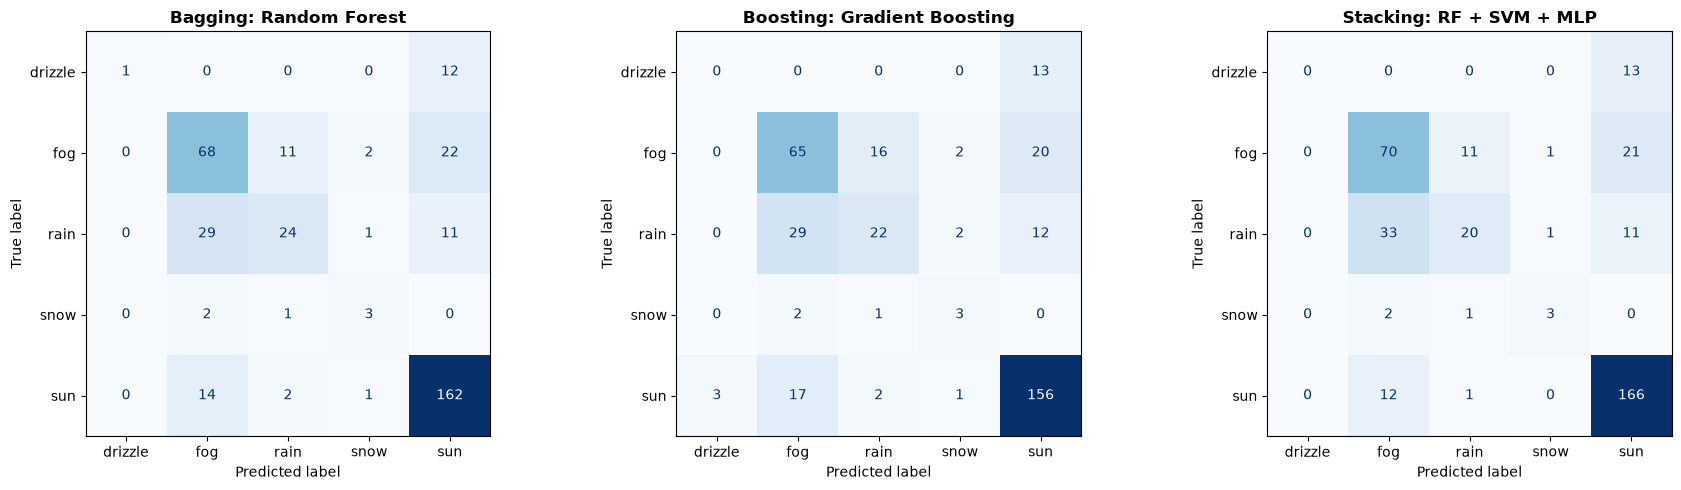

In [9]:
# Matrizes de Confusão Comparativas dos 3 Pilares
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pilares = [
    ('Bagging: Random Forest', rf_clf),
    ('Boosting: Gradient Boosting', gb_clf),
    ('Stacking: RF + SVM + MLP', stacking_clf)
]

for idx, (titulo, mod) in enumerate(pilares):
    pred = mod.predict(X_test)
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
    disp.plot(ax=axes[idx], cmap='Blues', colorbar=False)
    axes[idx].set_title(titulo, fontsize=12, fontweight='bold')
    axes[idx].grid(False)

plt.tight_layout()
plt.show()


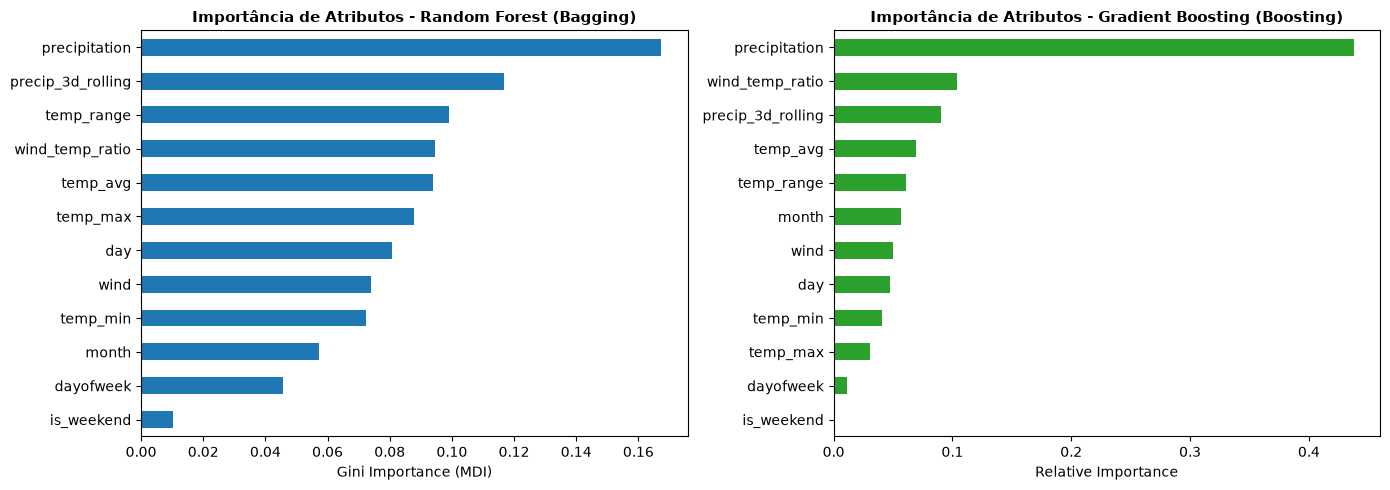

In [10]:
# Importância dos Atributos Climáticos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
feat_rf = pd.Series(rf_clf.feature_importances_, index=feature_cols).sort_values(ascending=True)
feat_gb = pd.Series(gb_clf.feature_importances_, index=feature_cols).sort_values(ascending=True)

feat_rf.plot(kind='barh', ax=axes[0], color='#1f77b4')
axes[0].set_title('Importância de Atributos - Random Forest (Bagging)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Gini Importance (MDI)')

feat_gb.plot(kind='barh', ax=axes[1], color='#2ca02c')
axes[1].set_title('Importância de Atributos - Gradient Boosting (Boosting)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Relative Importance')

plt.tight_layout()
plt.show()


## 10. Conclusões e Síntese Técnica

1. **Superação Consistente do Baseline:**
   - A árvore de decisão individual alcançou **56,01%** de acurácia no teste e sofreu forte sobreajuste.
   - Todos os métodos ensemble superaram expressivamente o modelo individual: **Bagging atingiu 71,31%**, **Stacking atingiu 70,76%** e **Random Forest obteve 70,49%**, proporcionando um salto superior a **15 pontos percentuais** de precisão.

2. **Diferenças Fundamentais Observadas:**
   - **Bagging e Random Forest:** Mostraram-se os mais estáveis contra o ruído das medições climáticas diárias, reduzindo substancialmente a variância.
   - **Boosting:** Convergiu rapidamente para alta sensibilidade na classe majoritária (`sun`) e em `rain`, sendo `Gradient Boosting` superior ao `AdaBoost`.
   - **Stacking:** Aproveitou a complementaridade entre o hiperplano de separação do SVM, a flexibilidade não-linear da Rede Neural MLP e a robustez do Random Forest, atingindo um dos desempenhos mais sólidos de generalização.

3. **Relevância dos Atributos:**
   - As variáveis com maior poder preditivo para condições climáticas foram a **`precipitation`**, a **amplitude térmica diária (`temp_range`)** e a média móvel recente de chuva (**`precip_3d_rolling`**).
